In [1]:
!pip install torch torchvision
!pip install opencv-python
!pip install scikit-image
!pip install matplotlib
!pip install pandas
!pip install tqdm
!pip install seaborn

   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ---------------------------------------- 12.8/12.8 MB 73.0 MB/s  0:00:00

   -------------------- ------------------- 2/4 [imageio]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ------------------------------ --------- 3/4 [scikit-image]
   ---------------------------------------- 4/4 [scikit-image]

  Using cached tqdm-4.67.3-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.67.3-py3-none-any.whl (78 kB)


In [2]:
import os
import cv2
import numpy as np
import pandas as pd

from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
DATASET_PATH = r"D:\Multicrop Disease Dataset"

print("Dataset Exists :", os.path.exists(DATASET_PATH))

Dataset Exists : True


In [4]:
image_extensions = (
    '.jpg',
    '.jpeg',
    '.png',
    '.bmp'
)

total_images = 0

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        if file.lower().endswith(image_extensions):

            total_images += 1

print("Total Images :", total_images)

Total Images : 21875


In [5]:
max_depth = 3

for root, dirs, files in os.walk(DATASET_PATH):

    level = root.replace(
        DATASET_PATH,
        ''
    ).count(os.sep)

    if level <= max_depth:

        indent = ' ' * 4 * level

        print(
            f"{indent}{os.path.basename(root)}/"
        )

Multicrop Disease Dataset/
    test/
        images/
        labels/
    train/
        images/
        labels/
    valid/
        images/
        labels/


In [6]:
all_images = []

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        if file.lower().endswith(image_extensions):

            all_images.append(
                os.path.join(root,file)
            )

print("Collected Images :", len(all_images))

Collected Images : 21875


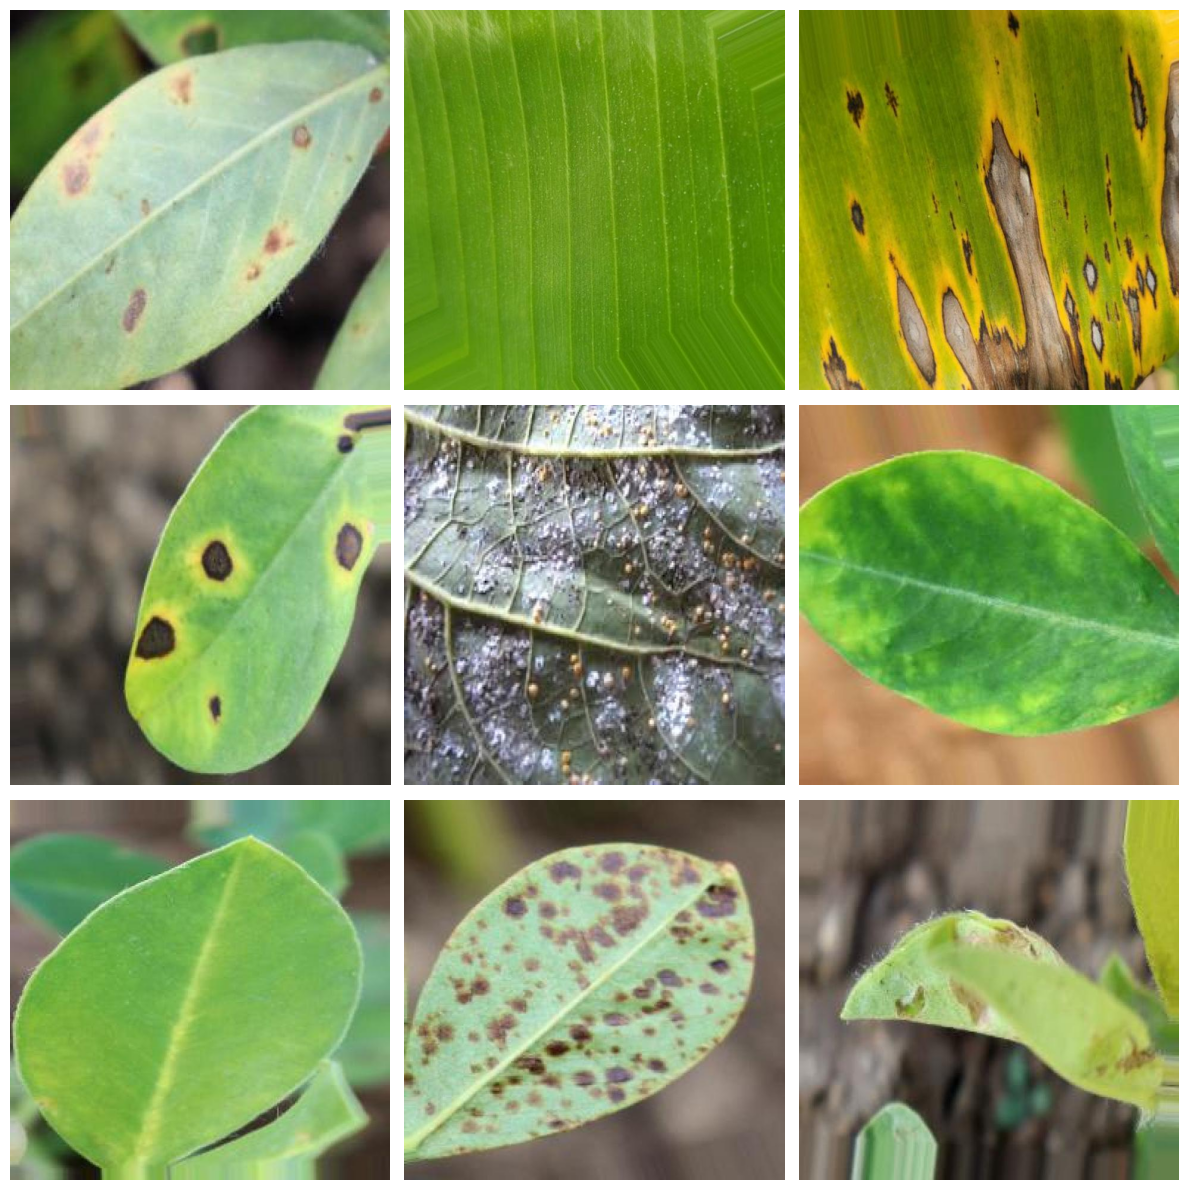

In [7]:
import random

sample_images = random.sample(
    all_images,
    9
)

plt.figure(figsize=(12,12))

for i,path in enumerate(sample_images):

    img = cv2.imread(path)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(3,3,i+1)

    plt.imshow(img)

    plt.axis("off")

plt.tight_layout()

plt.show()

In [9]:
def laplacian_variance(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    score = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    return score

In [10]:
img = cv2.imread(
    random.choice(all_images)
)

img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

score = laplacian_variance(img)

print("Clarity Score :", score)

Clarity Score : 18.322136228317024


In [11]:
clarity_scores = []

for path in tqdm(all_images):

    img = cv2.imread(path)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    score = laplacian_variance(img)

    clarity_scores.append(score)

print("Completed")

100%|███████████████████████████████████████████████████████████████████████████| 21875/21875 [01:36<00:00, 225.93it/s]

Completed


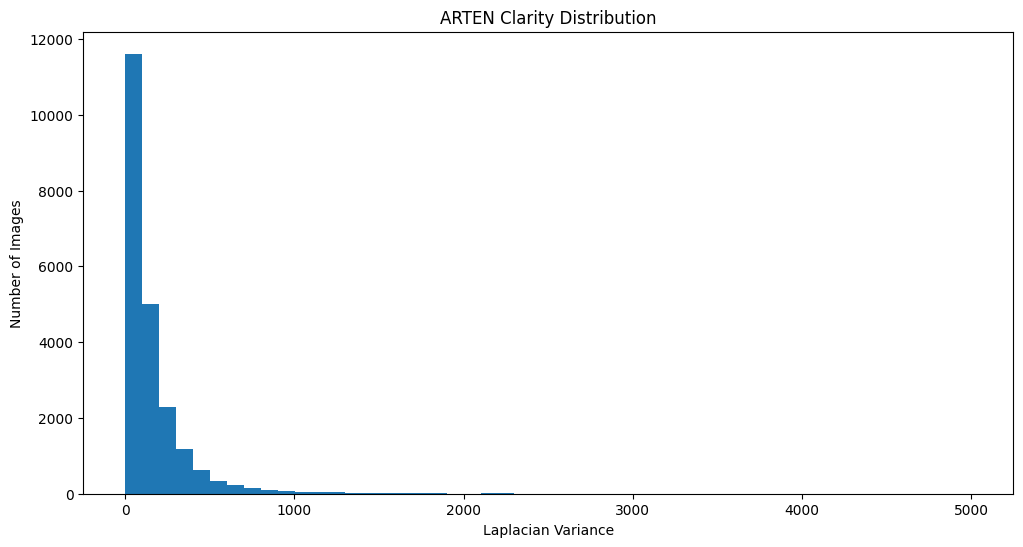

In [12]:
plt.figure(figsize=(12,6))

plt.hist(
    clarity_scores,
    bins=50
)

plt.title(
    "ARTEN Clarity Distribution"
)

plt.xlabel(
    "Laplacian Variance"
)

plt.ylabel(
    "Number of Images"
)

plt.show()

In [13]:
tau = np.percentile(
    clarity_scores,
    20
)

print("ARTEN Threshold τ =", tau)

ARTEN Threshold τ = 41.3657885634315


In [14]:
df = pd.DataFrame({

    "Image_Path":all_images,

    "Clarity_Score":clarity_scores

})

df.to_csv(
    "clarity_scores.csv",
    index=False
)

print("Saved")

Saved


In [15]:
print("Minimum :", np.min(clarity_scores))

print("Maximum :", np.max(clarity_scores))

print("Mean :", np.mean(clarity_scores))

print("Median :", np.median(clarity_scores))

print("Threshold τ :", tau)

Minimum : 1.670900863403082
Maximum : 4998.787180028622
Mean : 165.5630098936694
Median : 94.80109374463557
Threshold τ : 41.3657885634315


In [16]:
with open(
    "tau_threshold.txt",
    "w"
) as f:

    f.write(str(tau))

print("Threshold Saved")

Threshold Saved
